# E-handelsrapport


Gruppmedlemmar: Jacob Edlund, Katerina Zezulova, Natasa Stankovic, Charlie Selwyn, Tanveer Hasan

### Data
Vår data består i en CSV-fil innehållandes information om säljstatistik i olika svenska städer, med tillhörande information om kategori, intäkt, pris, datum, antal enheter.



### Syfte
Syftet med denna rapport är att analysera försäljningsdata och vara underlag för ledningens kommande beslut om nästa kampanjperiod. Rapporten undersöker också den eventuella förekomsten av avvikande mönster för försäljningen.

## Förberedelser


In [2]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.ecommerce import CommerceAnalyzer
from src import metrics
from src import viz


## Underlag
Översikt över den tillgängliga datan som utgör underlag för rapporten. Mellan 1 januari och 30 juni 2024 finns 2500 unika försäljningsordrar dokumenterade.

In [12]:
analyzer = CommerceAnalyzer(PROJECT_ROOT / "data" / "ecommerce_sales.csv")
df = analyzer.dataframe

summary = analyzer.summary()
display(pd.DataFrame(summary.items(), columns=['Nyckeltal', 'Värde']).round(0))


,Nyckeltal,Värde
0,total_revenue,3502767.0
1,total_units,7463.0
2,order_count,2500.0
3,aov,1401.0


## Nyckeltal
De nyckeltal vi använt är:
- Total intäkt
- Antal sålda enheter
- Antal ordrar
- Genomsnittligt ordervärde
- Intäkt per stad
- Intäkt per kategori
- Top 3 kategorier efter intäkt

In [ ]:
summary = analyzer.summary()
display(pd.DataFrame([summary]).rename(columns={
    "total_revenue": "Total intäkt",
    "total_units": "Antal sålda enheter",
    "order_count": "Antal order",
    "aov": "AOV"
}).round(2))


,Total intäkt,Antal sålda enheter,Antal order,AOV
0,3502767.23,7463,2500,1401.11


## 1. Vad säljer?
Den kategori som säljer mest är elektronik, följt av sport och kläder.

In [19]:
category_revenue = analyzer.revenue_by_category()
display(category_revenue.style.format({"revenue" : "{:.0f}"}).hide(axis="index"))


category,revenue
Electronics,1364228
Sports,734653
Clothing,586745
Home,511071
Beauty,163054
Toys,143016


## 2. Var säljer vi?


In [11]:
city_revenue = analyzer.revenue_by_city()
display(city_revenue)


,city,revenue
2,Stockholm,1227201.94
0,Göteborg,859019.65
1,Malmö,567926.32
3,Uppsala,551478.42
4,Västerås,297140.90


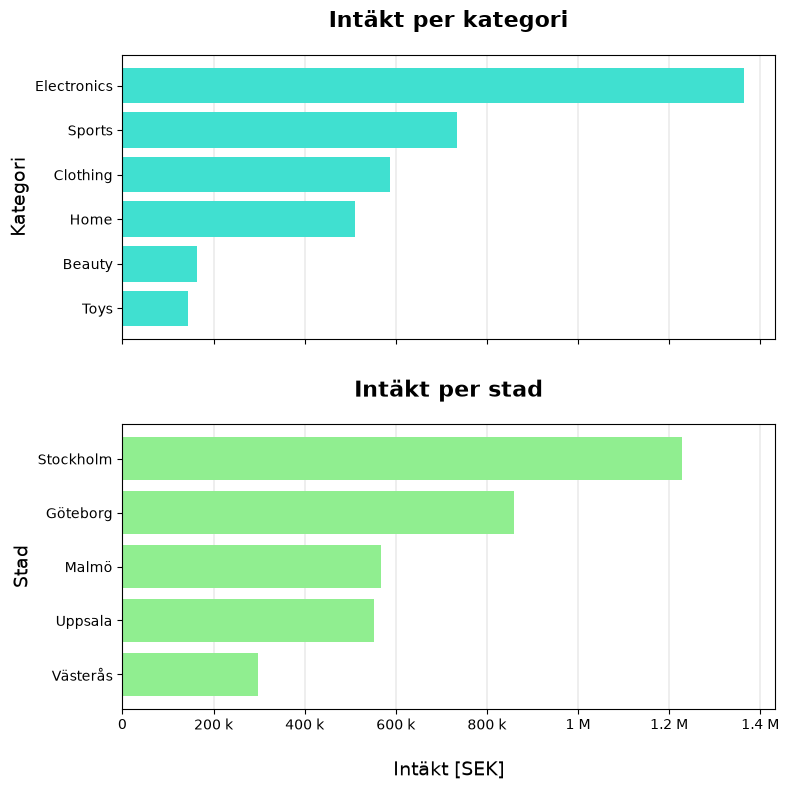

In [12]:
viz.plot_revenue_category_city(category_revenue, city_revenue)


## 3. När säljer vi?


,date,revenue
0,January 2024,664083.32
1,February 2024,548462.03
2,March 2024,487602.00
3,April 2024,580194.83
4,May 2024,632165.16
5,June 2024,590259.89


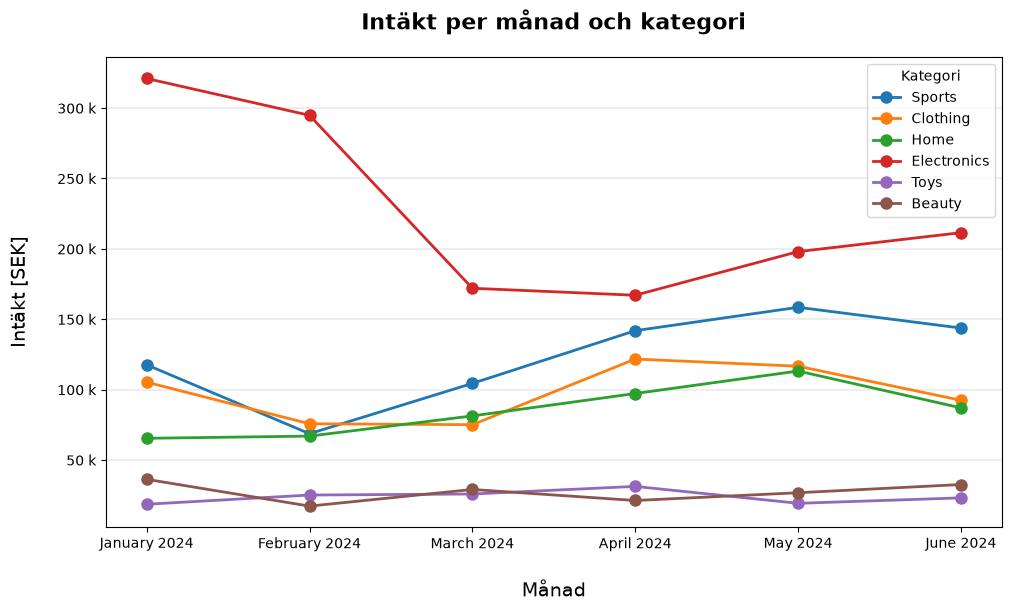

In [13]:
monthly_revenue = analyzer.revenue_by_month()
display(monthly_revenue)

analyzer.plot_monthly_revenue()


## 4. Hur ser en typisk order ut?


In [14]:
order_stats = analyzer.order_value_distribution()
display(pd.DataFrame([{
    "AOV": summary["aov"],
    "Median": order_stats["median_revenue"],
    "Minimum": order_stats["min_revenue"],
    "Maximum": order_stats["max_revenue"],
}]).round(2))


,AOV,Median,Minimum,Maximum
0,1401.11,1088.69,50.0,9192.6


,number of orders,percentages
revenue_group,,
50.00 - 465.48,484,19.36
465.48 - 880.95,539,21.56
880.95 - 1296.43,435,17.40
1296.43 - 5244.51,1005,40.20
5244.51 - 9192.60,37,1.48


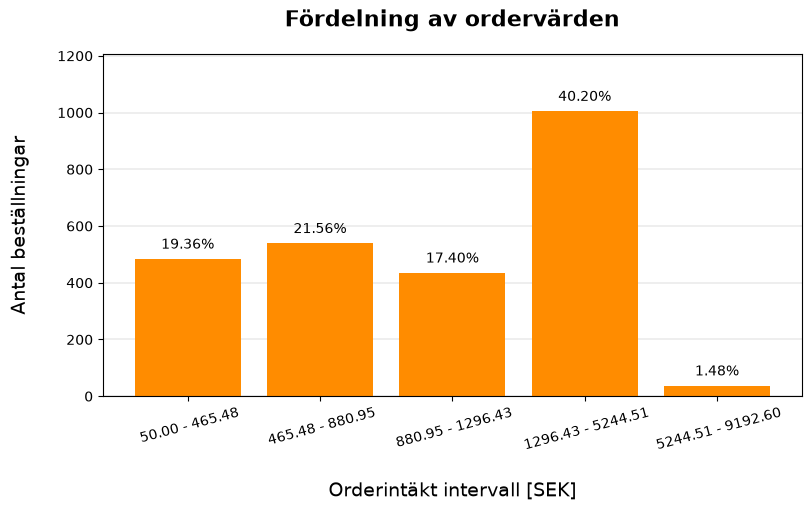

In [15]:
order_ranges = metrics.calculate_order_ranges(df)
display(order_ranges)
viz.plot_order_value_distribution(order_ranges)


## 5. Topp-3 kategorier efter intäkt


In [16]:
top_categories = analyzer.revenue_top_3_categories()
display(top_categories)


,category,revenue
2,Electronics,1364228.07
4,Sports,734653.42
1,Clothing,586744.91


## 6. Finns det avvikelser att undersöka?


## Rekommendationer


## Avgränsningar
